# Análisis exploratorio de datos musicales

Trabajo individual del módulo Herramientas Básicas de Visualización de Datos del diplomado de la UPB. Este notebook responde 20 preguntas del ejercicio con el CSV obtenido durante el módulo mediante una aplicación personal de la Spotify Web API. El procedimiento exacto y la fecha de extracción no se conservaron.

Los resultados describen **este archivo**, no todo el catálogo de Spotify ni la popularidad histórica en el año de lanzamiento. El CSV no forma parte del repositorio; [datos y contexto de la API](../data/README.md).

## Preparación y comprobaciones

Se lee el archivo desde la raíz del repositorio o desde la carpeta del notebook. Los valores faltantes se tratan según la pregunta: una fila sin artista sigue siendo útil para calcular la duración media.

In [1]:
import os
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd

candidates = [Path(os.environ["SPOTIFY_CSV"])] if "SPOTIFY_CSV" in os.environ else [
    Path("data/spotify_artists.csv"), Path("../data/spotify_artists.csv")
]
data_path = next((path for path in candidates if path.exists()), None)
if data_path is None:
    raise FileNotFoundError("Coloca una copia autorizada en data/spotify_artists.csv")

df = pd.read_csv(data_path)
expected = {"name", "artist", "year", "duration_ms", "popularity", "energy", "danceability", "tempo"}
missing_columns = expected - set(df.columns)
if missing_columns:
    raise ValueError(f"Faltan columnas: {sorted(missing_columns)}")
for column in ["year", "duration_ms", "popularity", "energy", "danceability", "tempo"]:
    df[column] = pd.to_numeric(df[column], errors="coerce")

print(f"Registros: {len(df):,} | Columnas: {df.shape[1]}")
print("Valores faltantes por columna:")
print(df.isna().sum().to_string())
print(f"Años: {df['year'].min():.0f}–{df['year'].max():.0f}")

Registros: 163,661 | Columnas: 8
Valores faltantes por columna:
name              0
artist          871
year              0
duration_ms       0
popularity        0
energy            0
danceability      0
tempo             0
Años: 1921–2020


## Preguntas 1–6: tamaño, títulos, décadas y faltantes

Se distinguen **registros** de canciones únicas: el archivo no incluye un identificador de pista que permita deduplicar versiones con certeza.

In [2]:
# 1. Número de registros y 2. tiempo de escucha acumulado.
total_days = df["duration_ms"].dropna().sum() / 86_400_000
print(f"1. Registros: {len(df):,}")
print(f"2. Escucha continua: {total_days:.1f} días (≈ {round(total_days)} días)")

# 3–4. Coincidencia exacta de título y mayor popularidad entre esos registros.
love = df.loc[df["name"].eq("Love")].copy()
love_top = love.sort_values(
    ["popularity", "energy", "artist"], ascending=[False, False, True]
).iloc[0]
print(f"3. Registros titulados 'Love': {len(love)}")
print(f"4. Mayor popularidad entre ellos: {love_top['artist']} ({love_top['popularity']:.0f})")

# 5. Década más representada; 6. columnas incompletas.
decade = (df["year"] // 10 * 10).astype("Int64")
decade_counts = decade.value_counts().sort_index()
print(f"5. Década con más registros: {decade_counts.idxmax()} ({decade_counts.max():,})")
print("6. Columnas con faltantes:", df.isna().sum().loc[lambda s: s.gt(0)].to_dict())

1. Registros: 163,661
2. Escucha continua: 437.2 días (≈ 437 días)
3. Registros titulados 'Love': 18
4. Mayor popularidad entre ellos: Lana Del Rey (70)
5. Década con más registros: 1990 (19,505)
6. Columnas con faltantes: {'artist': 871}


## Pregunta 7: tempo de pistas muy populares después de 2015

El filtro usa simultáneamente `popularity > 90` y `year > 2015`. El tempo se expresa en pulsaciones por minuto (BPM); rápido/lento aquí significa mayor/menor **tempo**, no menor duración.

Registros filtrados: 30
Mayor tempo: Stuck with U (with Justin Bieber) (2020; 178.76 BPM)
Menor tempo: HIGHEST IN THE ROOM (2019; 76.47 BPM)
Año con más registros en este filtro: 2019 (14)


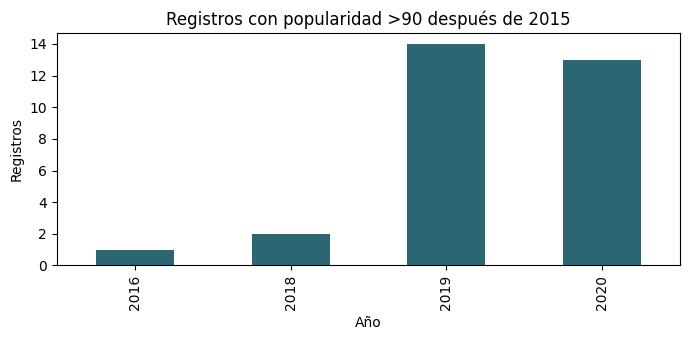

In [3]:
selected = df.loc[df["popularity"].gt(90) & df["year"].gt(2015)].dropna(subset=["tempo"])
fastest = selected.loc[selected["tempo"].idxmax()]
slowest = selected.loc[selected["tempo"].idxmin()]
counts = selected.groupby("year").size().sort_index()
print(f"Registros filtrados: {len(selected)}")
print(f"Mayor tempo: {fastest['name']} ({fastest['year']:.0f}; {fastest['tempo']:.2f} BPM)")
print(f"Menor tempo: {slowest['name']} ({slowest['year']:.0f}; {slowest['tempo']:.2f} BPM)")
print(f"Año con más registros en este filtro: {counts.idxmax():.0f} ({counts.max()})")

ax = counts.plot.bar(figsize=(7, 3.5), color="#2c6673")
ax.set(title="Registros con popularidad >90 después de 2015", xlabel="Año", ylabel="Registros")
plt.tight_layout()
plt.show()

## Preguntas 8–11: extremos y artistas

Para consultas sobre artistas solo se excluyen las filas sin `artist`. «Desde 1960» incluye todos los años **a partir** de 1960, no únicamente ese año. En la pregunta 11 se vuelve a filtrar por el artista identificado en la 10.

In [4]:
with_artist = df.dropna(subset=["artist"])
longest = with_artist.loc[with_artist["duration_ms"].idxmax()]
most_popular = with_artist.sort_values(
    ["popularity", "energy", "name"], ascending=[False, False, True]
).iloc[0]
print(f"8a. Mayor duración: {longest['name']} — {longest['artist']} ({longest['duration_ms']/60_000:.1f} min)")
print(f"8b. Mayor popularidad registrada: {most_popular['name']} ({most_popular['year']:.0f})")

michael = with_artist.loc[with_artist["artist"].eq("Michael Jackson")]
michael_top = michael.sort_values(
    ["energy", "popularity", "name"], ascending=[False, False, True]
).iloc[0]
print(f"9. Mayor energía de Michael Jackson: {michael_top['name']} ({michael_top['energy']:.3f})")

since_1960 = with_artist.loc[with_artist["year"].ge(1960)]
artist_counts = since_1960["artist"].value_counts()
top_artist = artist_counts.index[0]
artist_best = since_1960.loc[since_1960["artist"].eq(top_artist)].sort_values(
    ["popularity", "energy", "name"], ascending=[False, False, True]
).iloc[0]
print(f"10. Más registros desde 1960: {top_artist} ({artist_counts.iloc[0]})")
print(f"11. Mayor popularidad de ese artista: {artist_best['name']} ({artist_best['popularity']:.0f})")

8a. Mayor duración: Brown Noise - 90 Minutes — Sound Dreamer (90.1 min)
8b. Mayor popularidad registrada: death bed (coffee for your head) (feat. beabadoobee) (2020)
9. Mayor energía de Michael Jackson: Smooth Criminal - 2012 Remaster (0.981)
10. Más registros desde 1960: Bob Dylan (550)
11. Mayor popularidad de ese artista: Knockin' On Heaven's Door (74)


## Pregunta 12: una pista por año, 1980–2020

El criterio es mayor valor de popularidad **guardado en el CSV**. `energy` solo rompe empates de popularidad; nombre y artista fijan un orden estable si aún hay empate. El rango incluye 2020 y se comprueba que haya 41 años.

In [5]:
annual = df.loc[df["year"].between(1980, 2020)].dropna(
    subset=["year", "name", "popularity", "energy"]
).copy()
annual["year"] = annual["year"].astype(int)
annual["artist"] = annual["artist"].fillna("")
top_by_year = annual.sort_values(
    ["year", "popularity", "energy", "name", "artist"],
    ascending=[True, False, False, True, True], kind="stable"
).drop_duplicates("year", keep="first")
top_by_year = top_by_year[["year", "name", "artist", "popularity", "energy"]].sort_values("year")
assert top_by_year["year"].tolist() == list(range(1980, 2021))
print(f"Años representados: {len(top_by_year)}")
display(top_by_year.loc[top_by_year["year"].isin([1980, 2000, 2010, 2020])])

Años representados: 41


,year,name,artist,popularity,energy
82802,1980,Back In Black,AC/DC,82,0.700
84672,2000,In the End,Linkin Park,83,0.864
85584,2010,"Hey, Soul Sister",Train,82,0.886
86517,2020,death bed (coffee for your head) (feat. beabad...,Powfu,97,0.431


## Preguntas 13–14: popularidad y duración frente a energía

El histograma muestra la distribución de `popularity`. Para que el diagrama de dispersión sea legible se dibuja una muestra reproducible de 10.000 registros, mientras que el coeficiente de Pearson se calcula sobre **todos** los registros válidos.

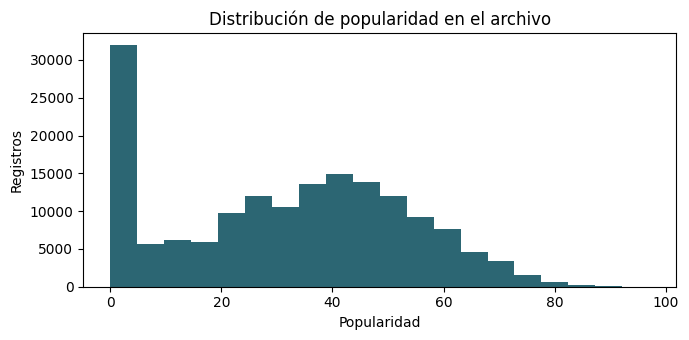

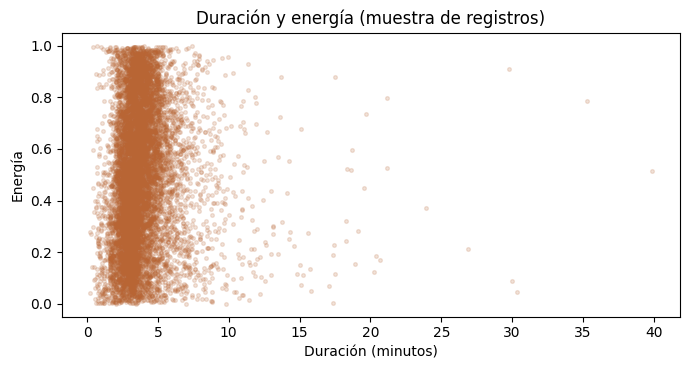

14. Correlación de Pearson, archivo completo: 0.038


In [6]:
ax = df["popularity"].dropna().plot.hist(bins=20, figsize=(7, 3.5), color="#2c6673")
ax.set(title="Distribución de popularidad en el archivo", xlabel="Popularidad", ylabel="Registros")
plt.tight_layout()
plt.show()

duration_energy = df.loc[df["duration_ms"].gt(0), ["duration_ms", "energy"]].dropna()
correlation = duration_energy.corr().iloc[0, 1]
sample = duration_energy.sample(n=min(10_000, len(duration_energy)), random_state=2026)
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.scatter(sample["duration_ms"] / 60_000, sample["energy"], s=7, alpha=0.18, color="#b86534")
ax.set(title="Duración y energía (muestra de registros)", xlabel="Duración (minutos)", ylabel="Energía")
plt.tight_layout()
plt.show()
print(f"14. Correlación de Pearson, archivo completo: {correlation:.3f}")

## Pregunta 15: distribución de *danceability*

Contar registros por año no mide *danceability*. Para comparar su **distribución** sin dibujar 100 cajas ilegibles, se agrupa por década y se muestra un diagrama de cajas. Se omiten los valores atípicos en la figura para facilitar la lectura, pero permanecen en los datos.

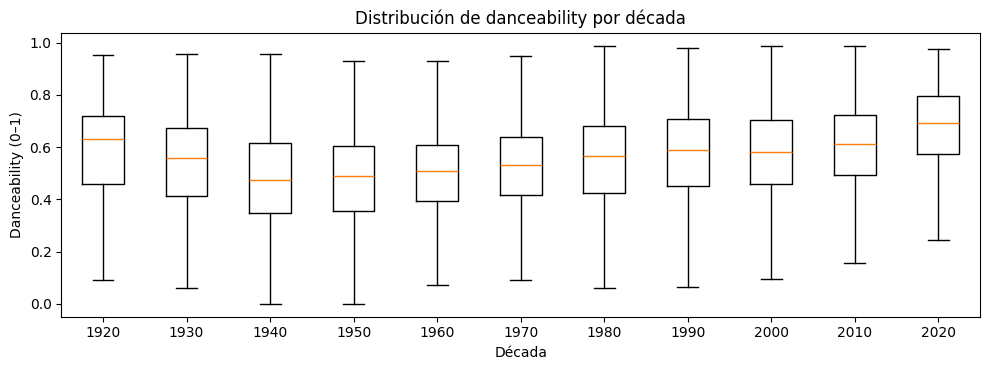

In [7]:
dance = df.loc[df["danceability"].between(0, 1), ["year", "danceability"]].dropna().copy()
dance["decade"] = (dance["year"].astype(int) // 10) * 10
decades = sorted(dance["decade"].unique())
groups = [dance.loc[dance["decade"].eq(decade), "danceability"].values for decade in decades]
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.boxplot(groups, tick_labels=[str(d) for d in decades], showfliers=False)
ax.set(title="Distribución de danceability por década", xlabel="Década", ylabel="Danceability (0–1)")
plt.tight_layout()
plt.show()

## Preguntas 16–18: tempo, energía y duración a lo largo del tiempo

La correlación popularidad–energía se calcula sobre todos los registros válidos. El gráfico de dispersión usa la misma muestra reproducible para legibilidad. La duración media anual se complementa con la mediana y el conteo por año: así se puede evaluar la sensibilidad del promedio a pistas excepcionalmente largas y la cobertura desigual.

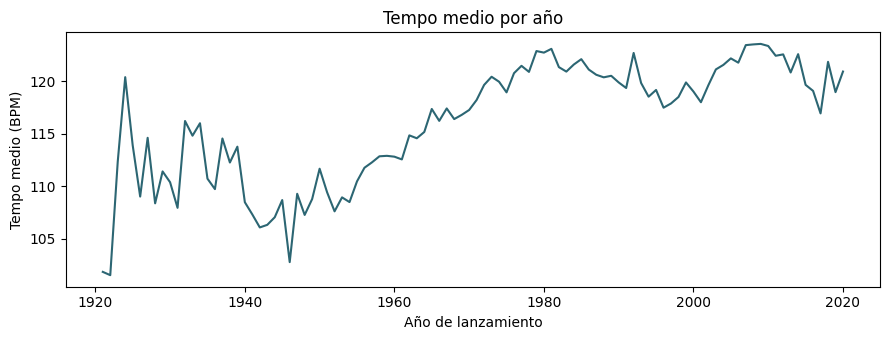

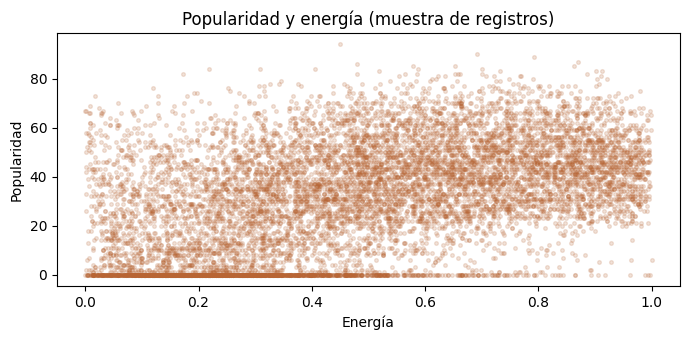

17. Correlación de Pearson, archivo completo: 0.492


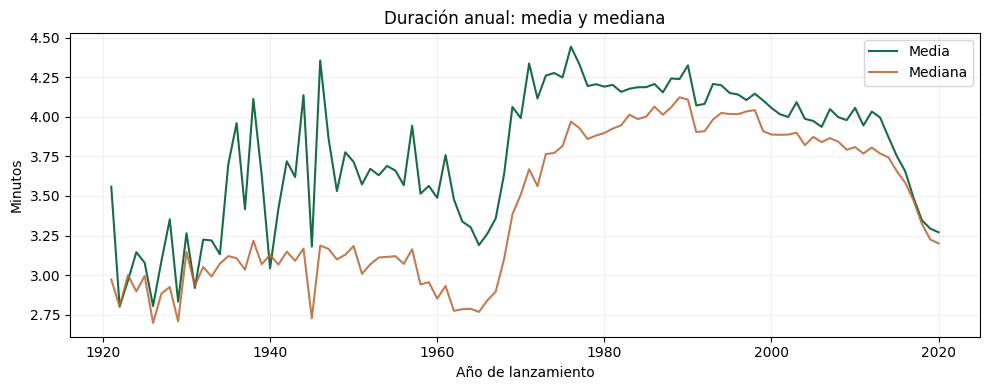

,size,mean,median
year,,,
1921,117,3.559,2.972
1980,1922,4.191,3.898
2000,1956,4.056,3.888
2020,1604,3.270,3.200


In [8]:
tempo_year = df.groupby("year")["tempo"].mean().dropna().sort_index()
ax = tempo_year.plot.line(figsize=(9, 3.5), color="#2c6673")
ax.set(title="Tempo medio por año", xlabel="Año de lanzamiento", ylabel="Tempo medio (BPM)")
plt.tight_layout()
plt.show()

pop_energy = df[["popularity", "energy"]].dropna()
correlation = pop_energy.corr().iloc[0, 1]
sample = pop_energy.sample(n=min(10_000, len(pop_energy)), random_state=2026)
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.scatter(sample["energy"], sample["popularity"], s=7, alpha=0.18, color="#b86534")
ax.set(title="Popularidad y energía (muestra de registros)", xlabel="Energía", ylabel="Popularidad")
plt.tight_layout()
plt.show()
print(f"17. Correlación de Pearson, archivo completo: {correlation:.3f}")

duration = df.loc[df["duration_ms"].gt(0), ["year", "duration_ms"]].dropna().copy()
duration["duration_min"] = duration["duration_ms"] / 60_000
duration_year = duration.groupby("year")["duration_min"].agg(["size", "mean", "median"]).sort_index()
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(duration_year.index, duration_year["mean"], label="Media", color="#186c45")
ax.plot(duration_year.index, duration_year["median"], label="Mediana", color="#b86534", alpha=0.85)
ax.set(title="Duración anual: media y mediana", xlabel="Año de lanzamiento", ylabel="Minutos")
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()
display(duration_year.loc[[1921, 1980, 2000, 2020]].round(3))

## Preguntas 19–20: promedio de energía y artistas únicos

El conteo de artistas excluye los nombres faltantes. Un nombre de artista no equivale necesariamente a una persona: puede representar grupos, colaboraciones o variantes de escritura.

In [9]:
michael = df.loc[df["artist"].eq("Michael Jackson"), "energy"].dropna()
print(f"19. Energía media de los registros de Michael Jackson: {michael.mean():.4f}")
print(f"20. Nombres de artista distintos, sin faltantes: {df['artist'].nunique(dropna=True):,}")

19. Energía media de los registros de Michael Jackson: 0.6931
20. Nombres de artista distintos, sin faltantes: 19,695


## Conclusiones y límites

- En este archivo, 1990 es la década con más registros. La duración media anual varía mucho: en 1980 es **4,191 min** y en 2020 **3,270 min**. La mediana y el número de registros por año ayudan a interpretar esa comparación.
- La selección anual contiene **41 pistas** de 1980 a 2020. Su popularidad es el valor guardado en el CSV, no una medida retrospectiva de popularidad en el lanzamiento.
- No se conserva el procedimiento de selección ni la fecha de extracción. Las asociaciones observadas no establecen causalidad ni permiten generalizar a todas las canciones de Spotify.